In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import GridSearchCV,RandomizedSearchCV,train_test_split,cross_val_predict,cross_val_score
from sklearn.metrics import r2_score,mean_absolute_error,mean_absolute_percentage_error,mean_squared_error
from sklearn.linear_model import LinearRegression,Ridge,Lasso

# EDA

In [70]:
df=pd.read_excel('data/premiums_rest.xlsx')
df.head()

,Age,Gender,Region,Marital_status,Number Of Dependants,BMI_Category,Smoking_Status,Employment_Status,Income_Level,Income_Lakhs,Medical History,Insurance_Plan,Annual_Premium_Amount
0,26,Male,Northwest,Unmarried,0,Normal,No Smoking,Salaried,<10L,6,Diabetes,Bronze,9053
1,29,Female,Southeast,Married,2,Obesity,Regular,Salaried,<10L,6,Diabetes,Bronze,16339
2,49,Female,Northeast,Married,2,Normal,No Smoking,Self-Employed,10L - 25L,20,High blood pressure,Silver,18164
3,30,Female,Southeast,Married,3,Normal,No Smoking,Salaried,> 40L,77,No Disease,Gold,20303
4,56,Male,Northeast,Married,3,Obesity,Occasional,Self-Employed,10L - 25L,14,Diabetes,Bronze,15610


In [71]:
df['genetical_risk']=0

In [72]:
df.shape

(29904, 14)

In [73]:
df.columns

Index(['Age', 'Gender', 'Region', 'Marital_status', 'Number Of Dependants',
       'BMI_Category', 'Smoking_Status', 'Employment_Status', 'Income_Level',
       'Income_Lakhs', 'Medical History', 'Insurance_Plan',
       'Annual_Premium_Amount', 'genetical_risk'],
      dtype='str')

In [74]:
df.columns=df.columns.str.replace(' ','_').str.lower()
df.columns

Index(['age', 'gender', 'region', 'marital_status', 'number_of_dependants',
       'bmi_category', 'smoking_status', 'employment_status', 'income_level',
       'income_lakhs', 'medical_history', 'insurance_plan',
       'annual_premium_amount', 'genetical_risk'],
      dtype='str')

In [75]:
df.dtypes

age                      int64
gender                     str
region                     str
marital_status             str
number_of_dependants     int64
bmi_category               str
smoking_status             str
employment_status          str
income_level               str
income_lakhs             int64
medical_history            str
insurance_plan             str
annual_premium_amount    int64
genetical_risk           int64
dtype: object

# Data transformation

## Handel Null Values

In [76]:
df.isnull().sum()

age                      0
gender                   0
region                   0
marital_status           0
number_of_dependants     0
bmi_category             0
smoking_status           9
employment_status        1
income_level             9
income_lakhs             0
medical_history          0
insurance_plan           0
annual_premium_amount    0
genetical_risk           0
dtype: int64

In [77]:
df.dropna(inplace=True)# droping every null value

In [78]:
df.duplicated().sum()# finding duplicate values
# df.drop_duplicates(inplace=True) if u want to delete the duplicate values

np.int64(0)

In [79]:
round(df.describe(),2)

,age,number_of_dependants,income_lakhs,annual_premium_amount,genetical_risk
count,29886.00,29886.00,29886.00,29886.00,29886.0
mean,43.40,2.38,23.36,20892.30,0.0
std,13.41,1.43,24.74,6936.81,0.0
min,26.00,-3.00,1.00,3625.00,0.0
25%,34.00,1.00,7.00,15697.25,0.0
50%,42.00,3.00,17.00,20489.00,0.0
75%,52.00,3.00,32.00,26360.00,0.0
max,356.00,5.00,930.00,43471.00,0.0


In [80]:
df[df.number_of_dependants<0].shape

(50, 14)

## number_of_dependants column tranformation

In [81]:
df[df.number_of_dependants<0]['number_of_dependants'].unique() # ask your data engineer about those negative values, he said they are positive values but while collecting data some mistake happened,so convert those negative values to positive

array([-1, -3])

In [82]:
df['number_of_dependants']=abs(df['number_of_dependants'])# converting negative values to positive
df[df.number_of_dependants<0]

,age,gender,region,marital_status,number_of_dependants,bmi_category,smoking_status,employment_status,income_level,income_lakhs,medical_history,insurance_plan,annual_premium_amount,genetical_risk


In [83]:
df.number_of_dependants.describe()

count    29886.000000
mean         2.385933
std          1.421137
min          0.000000
25%          1.000000
50%          3.000000
75%          3.000000
max          5.000000
Name: number_of_dependants, dtype: float64

In [84]:
df.select_dtypes(['float64','int64'])# getting numarical values

,age,number_of_dependants,income_lakhs,annual_premium_amount,genetical_risk
0,26,0,6,9053,0
1,29,2,6,16339,0
2,49,2,20,18164,0
3,30,3,77,20303,0
4,56,3,14,15610,0
...,...,...,...,...,...
29899,60,3,26,26370,0
29900,40,0,16,29496,0
29901,37,0,4,10957,0
29902,47,2,82,27076,0


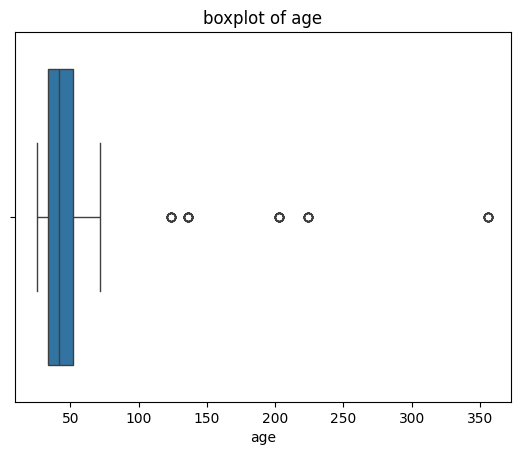

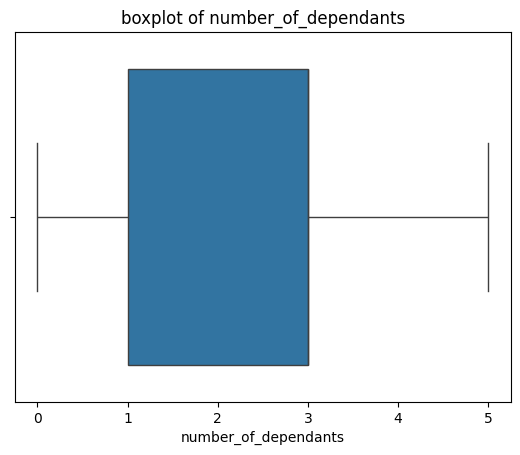

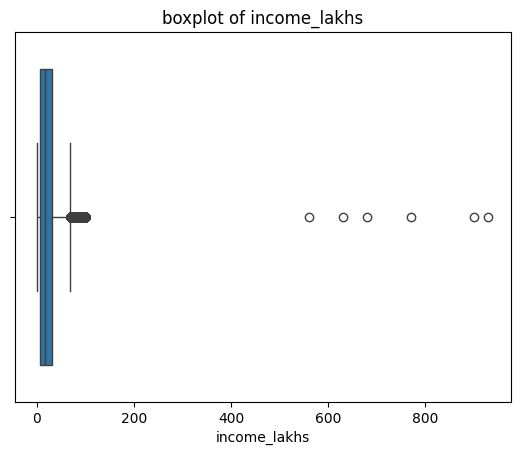

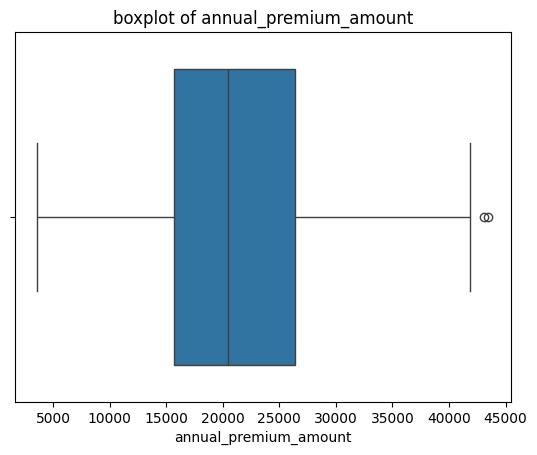

In [85]:
box =['age', 'number_of_dependants', 'income_lakhs',
       'annual_premium_amount']
for col in box:
    sns.boxplot(x=df[col])
    plt.title(f'boxplot of {col}')
    plt.show()

## removing outliers in age column

In [86]:
df[df['age']>100]['age'].unique()

array([224, 124, 136, 203, 356])

In [87]:
df1=df[df['age']<=100].copy()
df1.describe()

,age,number_of_dependants,income_lakhs,annual_premium_amount,genetical_risk
count,29828.000000,29828.000000,29828.000000,29828.000000,29828.0
mean,43.095380,2.387790,23.371530,20901.900563,0.0
std,11.041991,1.420641,24.751262,6928.457636,0.0
min,26.000000,0.000000,1.000000,6538.000000,0.0
25%,34.000000,1.000000,7.000000,15706.000000,0.0
50%,42.000000,3.000000,17.000000,20496.000000,0.0
75%,52.000000,3.000000,32.000000,26361.000000,0.0
max,72.000000,5.000000,930.000000,43471.000000,0.0


## using IQR to remove outliers in income_lakhs

<Axes: xlabel='income_lakhs', ylabel='Count'>

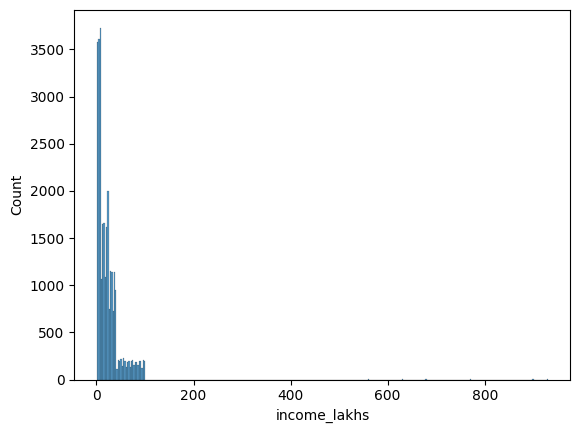

In [88]:
sns.histplot(df1['income_lakhs'])

In [89]:
def get_iqr(col):
    q1,q3=col.quantile([.25,.75])
    iqr=q3-q1
    lower_bound=q1-1.5*iqr
    upper_bound=q3+1.5*iqr
    return lower_bound,upper_bound

In [90]:
get_iqr(df1['income_lakhs'])

(-30.5, 69.5)

In [91]:
quantile_thresold=df1['income_lakhs'].quantile(0.999)
quantile_thresold

np.float64(100.0)

In [92]:
df1[df1['income_lakhs']>quantile_thresold]

,age,gender,region,marital_status,number_of_dependants,bmi_category,smoking_status,employment_status,income_level,income_lakhs,medical_history,insurance_plan,annual_premium_amount,genetical_risk
1598,51,Male,Northwest,Married,4,Obesity,No Smoking,Self-Employed,> 40L,560,High blood pressure,Gold,30692,0
4657,35,Female,Northeast,Unmarried,0,Overweight,No Smoking,Salaried,> 40L,630,Diabetes,Gold,24010,0
5399,43,Male,Southeast,Married,3,Obesity,Regular,Salaried,> 40L,900,Diabetes & Thyroid,Gold,30848,0
6149,37,Female,Southeast,Married,3,Normal,No Smoking,Freelancer,> 40L,930,Diabetes,Silver,15945,0
21176,59,Male,Northwest,Married,2,Obesity,Occasional,Self-Employed,> 40L,770,Thyroid,Gold,31115,0
24489,48,Male,Northeast,Married,4,Obesity,No Smoking,Salaried,> 40L,680,No Disease,Gold,28926,0


In [93]:
df1[df1['income_lakhs']>quantile_thresold].shape

(6, 14)

In [94]:
df2=df1[df1.income_lakhs<=quantile_thresold].copy()
df2.describe()

,age,number_of_dependants,income_lakhs,annual_premium_amount,genetical_risk
count,29822.000000,29822.000000,29822.000000,29822.000000,29822.0
mean,43.094896,2.387734,23.226343,20900.689223,0.0
std,11.042430,1.420644,22.455408,6928.192115,0.0
min,26.000000,0.000000,1.000000,6538.000000,0.0
25%,34.000000,1.000000,7.000000,15705.250000,0.0
50%,42.000000,3.000000,17.000000,20495.500000,0.0
75%,52.000000,3.000000,32.000000,26360.000000,0.0
max,72.000000,5.000000,100.000000,43471.000000,0.0


In [95]:
box

['age', 'number_of_dependants', 'income_lakhs', 'annual_premium_amount']

## Understanding dataset with the help of graphs

### Observe the plots, you can see the relations (correlation) of the columns

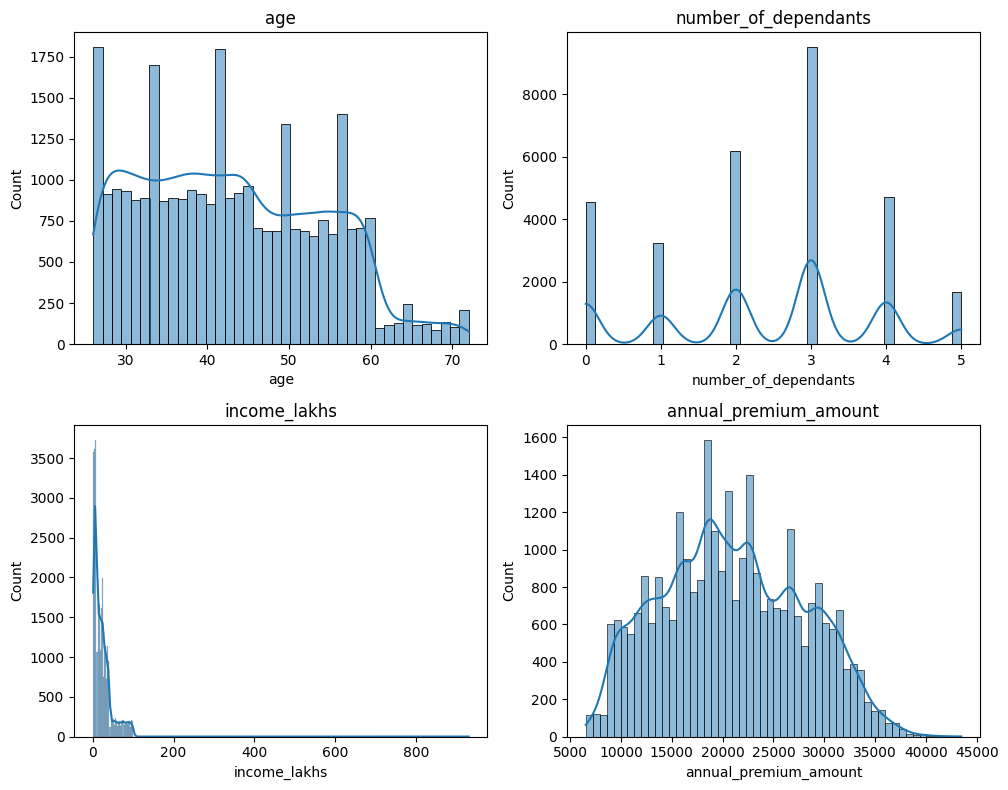

In [96]:
fig,axs=plt.subplots(nrows=2,ncols=2,figsize=(10,8))
for i,col in enumerate(box):
    ax=axs[i//2,i%2]
    sns.histplot(df1[col],kde=True,ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()
#plots with outliers

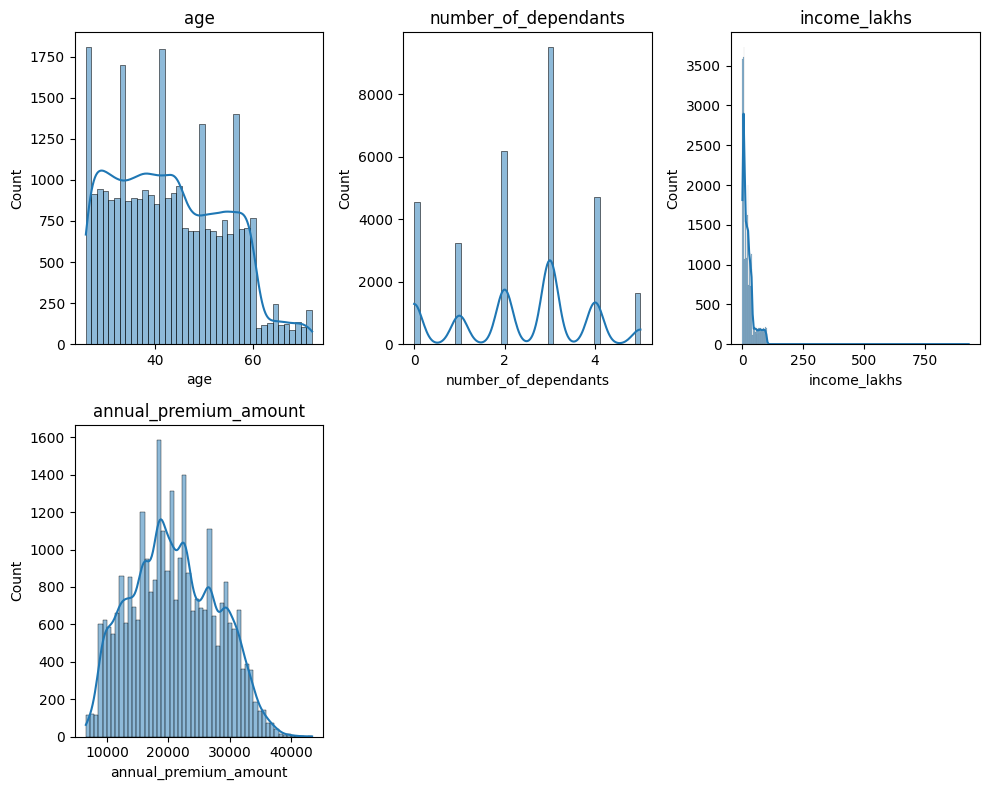

In [97]:
fig,axs=plt.subplots(nrows=2,ncols=3,figsize=(10,8))
for i,col in enumerate(box):
    ax=axs[i//3,i%3]
    sns.histplot(df1[col],kde=True,ax=ax)
    ax.set_title(col)
if len(box)%3!=0:
    for j in range(len(box),6):
        axs.flat[j].set_visible(False)
plt.tight_layout()
plt.show()
#plots with outliers

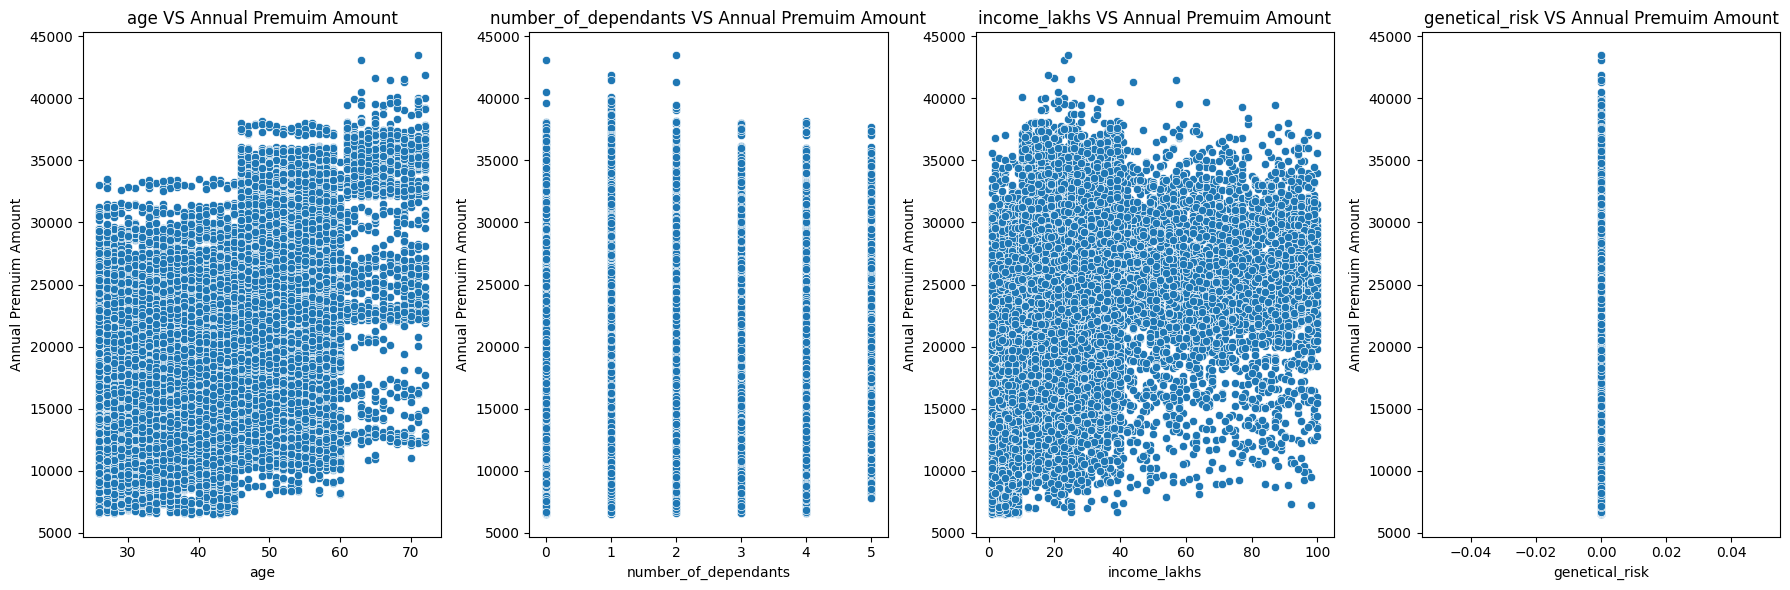

In [98]:
num=['age', 'number_of_dependants', 'income_lakhs','genetical_risk']#independent numeric columns
fig,axes=plt.subplots(1,len(num),figsize=(18,6))
for ax,col in zip(axes,num):
    sns.scatterplot(x=df2[col],y=df2['annual_premium_amount'],ax=ax)
    ax.set_title(f'{col} VS Annual Premuim Amount')
    ax.set_xlabel(col)
    ax.set_ylabel('Annual Premuim Amount')
plt.tight_layout()
plt.show()

In [99]:
categorical=df2.select_dtypes('string')
categorical.columns

Index(['gender', 'region', 'marital_status', 'bmi_category', 'smoking_status',
       'employment_status', 'income_level', 'medical_history',
       'insurance_plan'],
      dtype='str')

In [100]:
categorical_col=['gender', 'region', 'marital_status', 'bmi_category', 'smoking_status','employment_status', 'income_level', 'medical_history','insurance_plan']
for col in categorical_col:
    print(col, ":",df2[col].unique())
#here in smoking_status column we got some error values ('Smoking=0','Does Not Smoke','Not Smoking')all mean the same

gender : <ArrowStringArray>
['Male', 'Female']
Length: 2, dtype: str
region : <ArrowStringArray>
['Northwest', 'Southeast', 'Northeast', 'Southwest']
Length: 4, dtype: str
marital_status : <ArrowStringArray>
['Unmarried', 'Married']
Length: 2, dtype: str
bmi_category : <ArrowStringArray>
['Normal', 'Obesity', 'Overweight', 'Underweight']
Length: 4, dtype: str
smoking_status : <ArrowStringArray>
[    'No Smoking',        'Regular',     'Occasional', 'Does Not Smoke',
    'Not Smoking',      'Smoking=0']
Length: 6, dtype: str
employment_status : <ArrowStringArray>
['Salaried', 'Self-Employed', 'Freelancer']
Length: 3, dtype: str
income_level : <ArrowStringArray>
['<10L', '10L - 25L', '> 40L', '25L - 40L']
Length: 4, dtype: str
medical_history : <ArrowStringArray>
[                           'Diabetes',                 'High blood pressure',
                          'No Disease',      'Diabetes & High blood pressure',
                             'Thyroid',                       'Heart d

In [101]:
df2['smoking_status'].unique()

<ArrowStringArray>
[    'No Smoking',        'Regular',     'Occasional', 'Does Not Smoke',
    'Not Smoking',      'Smoking=0']
Length: 6, dtype: str

In [102]:
df2['smoking_status']=df2['smoking_status'].replace({
    'Smoking=0':'No Smoking',
    'Does Not Smoke':'No Smoking',
    'Not Smoking':'No Smoking'
},inplace=True)

C:\Users\Jeevan kumar\AppData\Local\Temp\ipykernel_21412\949633080.py:1: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment using an inplace method.
Such inplace method never works to update the original DataFrame or Series, because the intermediate object on which we are setting values always behaves as a copy (due to Copy-on-Write).

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' instead, to perform the operation inplace on the original object, or try to avoid an inplace operation using 'df[col] = df[col].method(value)'.

See the documentation for a more detailed explanation: https://pandas.pydata.org/pandas-docs/stable/user_guide/copy_on_write.html
  df2['smoking_status']=df2['smoking_status'].replace({


In [103]:
df2['smoking_status'].unique()

<ArrowStringArray>
['No Smoking', 'Regular', 'Occasional']
Length: 3, dtype: str

In [104]:
df2['gender'].value_counts(normalize=True)

gender
Male      0.549125
Female    0.450875
Name: proportion, dtype: float64

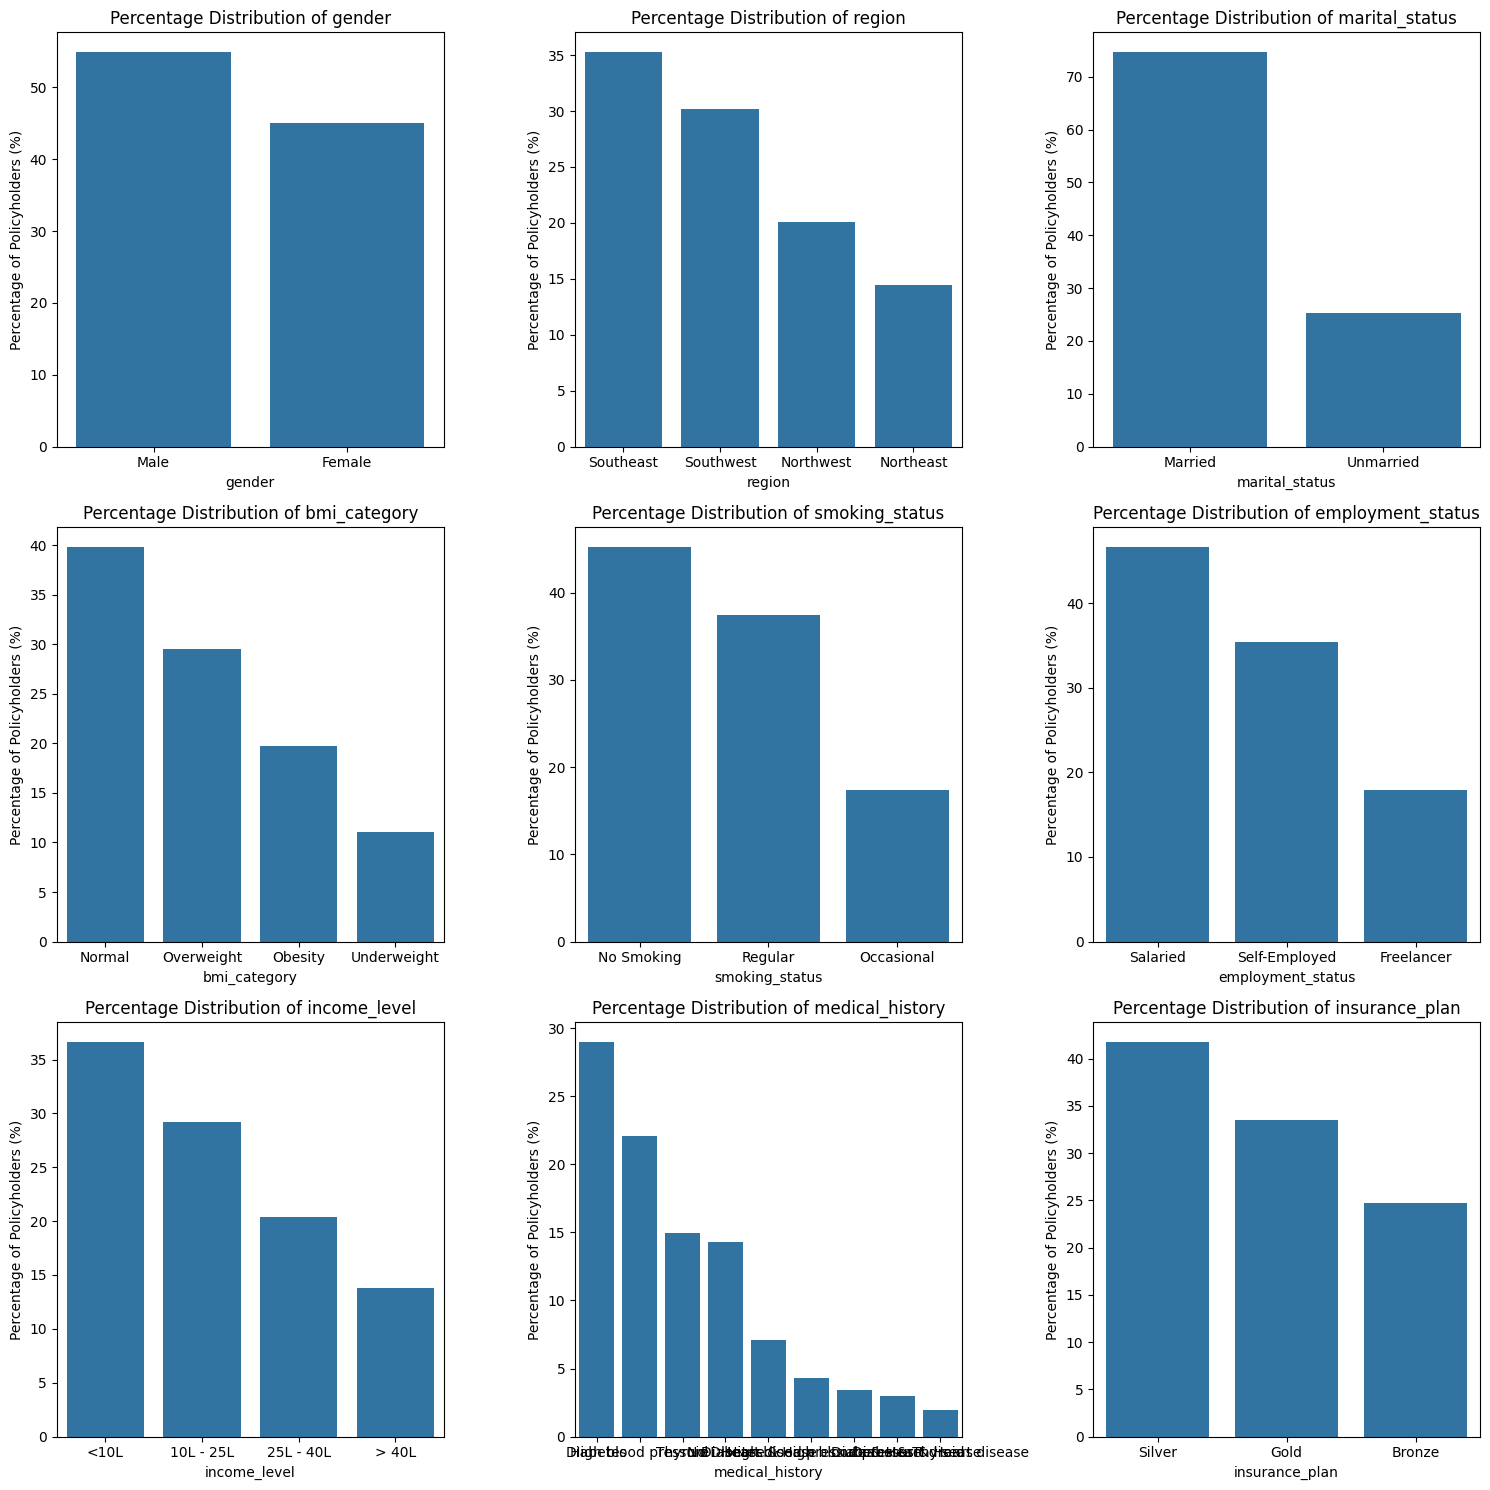

In [105]:
fig,axes=plt.subplots(3,3,figsize=(15,15))
axes=axes.flatten()
for ax,col in zip(axes,categorical_col):
    categorical_count=df2[col].value_counts(normalize=True)*100
    sns.barplot(x=categorical_count.index,y=categorical_count.values,ax=ax)
    ax.set_title(f'Percentage Distribution of {col}')
    ax.set_xlabel(col)
    ax.set_ylabel('Percentage of Policyholders (%)')
plt.tight_layout()
plt.show()

<Axes: xlabel='income_level'>

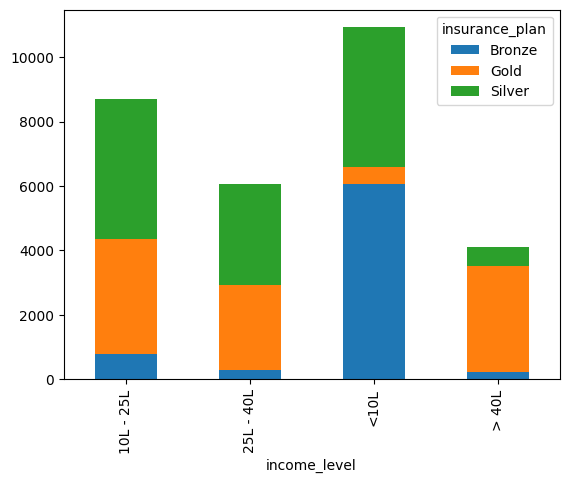

In [106]:
corsstab=pd.crosstab(df2['income_level'],df2['insurance_plan'])

corsstab.plot(kind='bar',stacked=True)

<Axes: xlabel='insurance_plan', ylabel='income_level'>

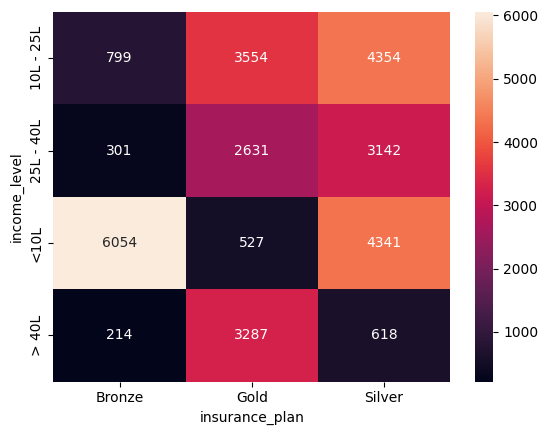

In [107]:
sns.heatmap(corsstab,annot=True,fmt='d')

# Feature Engineering

In [108]:
df2.head(2)

,age,gender,region,marital_status,number_of_dependants,bmi_category,smoking_status,employment_status,income_level,income_lakhs,medical_history,insurance_plan,annual_premium_amount,genetical_risk
0,26,Male,Northwest,Unmarried,0,Normal,No Smoking,Salaried,<10L,6,Diabetes,Bronze,9053,0
1,29,Female,Southeast,Married,2,Obesity,Regular,Salaried,<10L,6,Diabetes,Bronze,16339,0


In [109]:
df2.medical_history.unique()

<ArrowStringArray>
[                           'Diabetes',                 'High blood pressure',
                          'No Disease',      'Diabetes & High blood pressure',
                             'Thyroid',                       'Heart disease',
 'High blood pressure & Heart disease',                  'Diabetes & Thyroid',
            'Diabetes & Heart disease']
Length: 9, dtype: str

In [110]:
df2['medical_history'].str.split('&',expand=True).apply(lambda x:x.str.lower())

,0,1
0,diabetes,NaN
1,diabetes,NaN
2,high blood pressure,NaN
3,no disease,NaN
4,diabetes,NaN
...,...,...
29899,high blood pressure,NaN
29900,diabetes,thyroid
29901,no disease,NaN
29902,thyroid,NaN


In [111]:
df2[['disease1','disease2']]=df2['medical_history'].str.split('&',expand=True).apply(lambda x:x.str.lower())

In [112]:
df2.columns

Index(['age', 'gender', 'region', 'marital_status', 'number_of_dependants',
       'bmi_category', 'smoking_status', 'employment_status', 'income_level',
       'income_lakhs', 'medical_history', 'insurance_plan',
       'annual_premium_amount', 'genetical_risk', 'disease1', 'disease2'],
      dtype='str')

In [113]:
risk_score={
    'diabetes':6,
    'heart disease':8,
    'high blood pressure':6,
    'thyroid':5,
    'no disease':0,
    'none':0
}

In [114]:
df2['disease1'] = df2['disease1'].fillna('none')
df2['disease2'] = df2['disease2'].fillna('none')
df2['total_risk_score'] = 0

In [115]:
for disease in ['disease1','disease2']:
    df2['total_risk_score']+=df2[disease].map(risk_score)

max_score=df2['total_risk_score'].max()
min_score=df2['total_risk_score'].min()
df2['normalized_risk_score']=(df2['total_risk_score']-min_score)/(max_score-min_score)
df2.head(2)

,age,gender,region,marital_status,number_of_dependants,bmi_category,smoking_status,employment_status,income_level,income_lakhs,medical_history,insurance_plan,annual_premium_amount,genetical_risk,disease1,disease2,total_risk_score,normalized_risk_score
0,26,Male,Northwest,Unmarried,0,Normal,No Smoking,Salaried,<10L,6,Diabetes,Bronze,9053,0,diabetes,none,6.0,0.75
1,29,Female,Southeast,Married,2,Obesity,Regular,Salaried,<10L,6,Diabetes,Bronze,16339,0,diabetes,none,6.0,0.75


In [116]:
df2.sample(15)

,age,gender,region,marital_status,number_of_dependants,bmi_category,smoking_status,employment_status,income_level,income_lakhs,medical_history,insurance_plan,annual_premium_amount,genetical_risk,disease1,disease2,total_risk_score,normalized_risk_score
10818,57,Female,Southeast,Unmarried,0,Obesity,No Smoking,Salaried,> 40L,85,Thyroid,Gold,30858,0,thyroid,none,5.0,0.625
17147,29,Male,Southeast,Married,3,Normal,Regular,Salaried,<10L,9,High blood pressure,Bronze,12540,0,high blood pressure,none,6.0,0.750
3901,45,Male,Southeast,Unmarried,0,Obesity,No Smoking,Salaried,<10L,2,Thyroid,Bronze,12707,0,thyroid,none,5.0,0.625
29401,45,Female,Northeast,Married,3,Overweight,No Smoking,Salaried,<10L,4,High blood pressure & Heart disease,Bronze,15370,0,high blood pressure,heart disease,NaN,NaN
1566,42,Male,Southwest,Married,2,Obesity,Occasional,Self-Employed,25L - 40L,36,Thyroid,Silver,20465,0,thyroid,none,5.0,0.625
20549,46,Female,Southeast,Married,5,Obesity,No Smoking,Self-Employed,<10L,8,Heart disease,Silver,26274,0,heart disease,none,8.0,1.000
5930,35,Male,Southeast,Married,2,Overweight,Regular,Salaried,<10L,9,Diabetes,Bronze,14216,0,diabetes,none,6.0,0.750
15871,34,Male,Southeast,Married,4,Underweight,Occasional,Salaried,25L - 40L,34,Heart disease,Gold,27752,0,heart disease,none,8.0,1.000
16437,38,Female,Northwest,Married,2,Normal,Occasional,Self-Employed,<10L,1,High blood pressure,Bronze,9575,0,high blood pressure,none,6.0,0.750
9375,36,Male,Northeast,Married,4,Normal,Regular,Salaried,<10L,2,Diabetes,Silver,18218,0,diabetes,none,6.0,0.750


In [117]:
df2['disease2'].value_counts()

disease2
none                    26058
 heart disease           1595
 high blood pressure     1288
 thyroid                  881
Name: count, dtype: int64

In [118]:
df2['insurance_plan'].value_counts()

insurance_plan
Silver    12455
Gold       9999
Bronze     7368
Name: count, dtype: int64

In [119]:
df2['insurance_plan']=df2['insurance_plan'].map({'Bronze':1,'Silver':2,'Gold':3})#encoding insurance_plan column
df2.insurance_plan.unique()

array([1, 2, 3])

In [120]:
df2['income_level']=df2['income_level'].map({'<10L':1,'10L - 25L':2,'25L - 40L':3,'> 40L':4})#encoding income_level column
df2['income_level'].unique()

array([1, 2, 4, 3])

In [121]:
df2.select_dtypes('str').columns

Index(['gender', 'region', 'marital_status', 'bmi_category', 'smoking_status',
       'employment_status', 'medical_history', 'disease1', 'disease2'],
      dtype='str')

In [122]:
nominal_cols=['gender', 'region', 'marital_status', 'bmi_category', 'smoking_status','employment_status']#'medical_history', 'disease1', 'disease2' columns are not use here
df3=pd.get_dummies(df2,columns=nominal_cols,drop_first=True,dtype=int)#converting catogarical columns to numarical columns by using get_dummies
df3.head()

,age,number_of_dependants,income_level,income_lakhs,medical_history,insurance_plan,annual_premium_amount,genetical_risk,disease1,disease2,...,region_Southeast,region_Southwest,marital_status_Unmarried,bmi_category_Obesity,bmi_category_Overweight,bmi_category_Underweight,smoking_status_Occasional,smoking_status_Regular,employment_status_Salaried,employment_status_Self-Employed
0,26,0,1,6,Diabetes,1,9053,0,diabetes,none,...,0,0,1,0,0,0,0,0,1,0
1,29,2,1,6,Diabetes,1,16339,0,diabetes,none,...,1,0,0,1,0,0,0,1,1,0
2,49,2,2,20,High blood pressure,2,18164,0,high blood pressure,none,...,0,0,0,0,0,0,0,0,0,1
3,30,3,4,77,No Disease,3,20303,0,no disease,none,...,1,0,0,0,0,0,0,0,1,0
4,56,3,2,14,Diabetes,1,15610,0,diabetes,none,...,0,0,0,1,0,0,1,0,0,1


In [123]:
df3.columns

Index(['age', 'number_of_dependants', 'income_level', 'income_lakhs',
       'medical_history', 'insurance_plan', 'annual_premium_amount',
       'genetical_risk', 'disease1', 'disease2', 'total_risk_score',
       'normalized_risk_score', 'gender_Male', 'region_Northwest',
       'region_Southeast', 'region_Southwest', 'marital_status_Unmarried',
       'bmi_category_Obesity', 'bmi_category_Overweight',
       'bmi_category_Underweight', 'smoking_status_Occasional',
       'smoking_status_Regular', 'employment_status_Salaried',
       'employment_status_Self-Employed'],
      dtype='str')

In [124]:
df4=df3.drop(['medical_history', 'disease1', 'disease2','total_risk_score'],axis=1)
df4.head()

,age,number_of_dependants,income_level,income_lakhs,insurance_plan,annual_premium_amount,genetical_risk,normalized_risk_score,gender_Male,region_Northwest,region_Southeast,region_Southwest,marital_status_Unmarried,bmi_category_Obesity,bmi_category_Overweight,bmi_category_Underweight,smoking_status_Occasional,smoking_status_Regular,employment_status_Salaried,employment_status_Self-Employed
0,26,0,1,6,1,9053,0,0.75,1,1,0,0,1,0,0,0,0,0,1,0
1,29,2,1,6,1,16339,0,0.75,0,0,1,0,0,1,0,0,0,1,1,0
2,49,2,2,20,2,18164,0,0.75,0,0,0,0,0,0,0,0,0,0,0,1
3,30,3,4,77,3,20303,0,0.00,0,0,1,0,0,0,0,0,0,0,1,0
4,56,3,2,14,1,15610,0,0.75,1,0,0,0,0,1,0,0,1,0,0,1


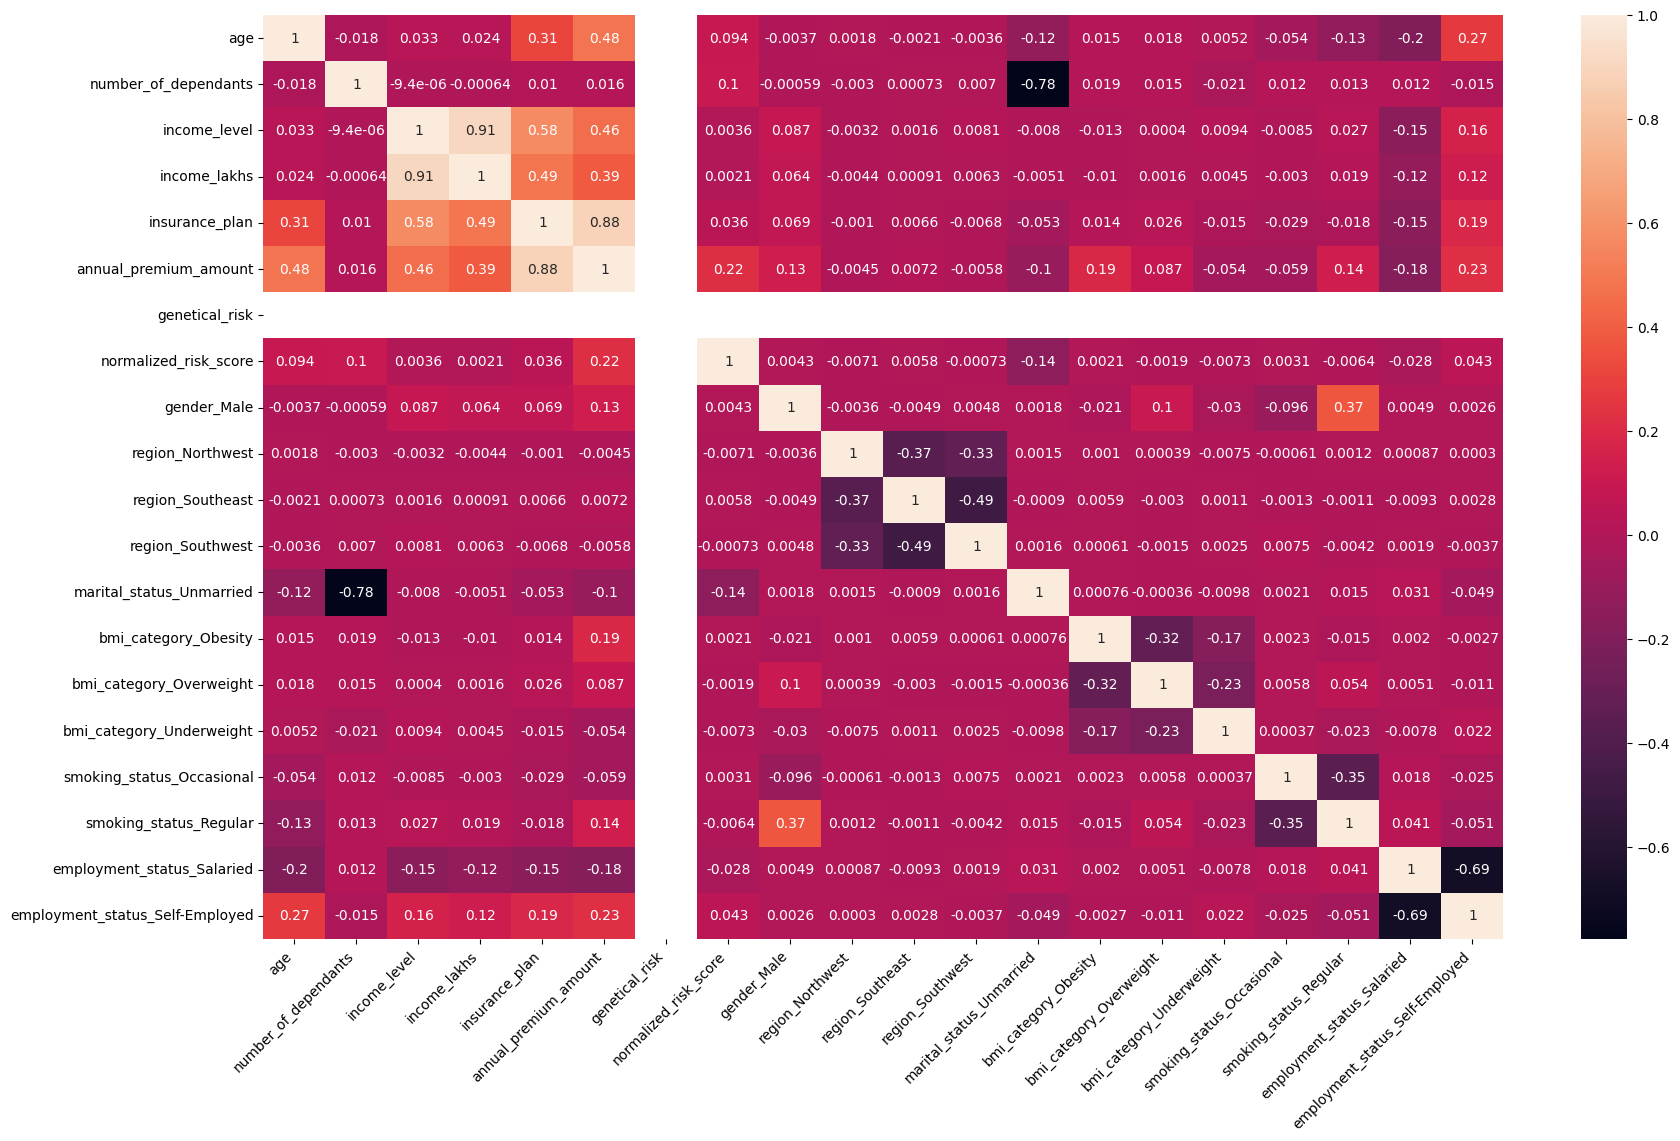

In [125]:
cn=df4.corr()

plt.figure(figsize=(20,12))
sns.heatmap(cn,annot=True)
plt.xticks(rotation=45,ha='right')
plt.yticks(rotation=0)
plt.tight_layout
plt.show()

In [126]:
#variation inflation factor

In [127]:
df4.head(2)

,age,number_of_dependants,income_level,income_lakhs,insurance_plan,annual_premium_amount,genetical_risk,normalized_risk_score,gender_Male,region_Northwest,region_Southeast,region_Southwest,marital_status_Unmarried,bmi_category_Obesity,bmi_category_Overweight,bmi_category_Underweight,smoking_status_Occasional,smoking_status_Regular,employment_status_Salaried,employment_status_Self-Employed
0,26,0,1,6,1,9053,0,0.75,1,1,0,0,1,0,0,0,0,0,1,0
1,29,2,1,6,1,16339,0,0.75,0,0,1,0,0,1,0,0,0,1,1,0


In [128]:
x=df4.drop(columns='annual_premium_amount')
y=df4['annual_premium_amount']

from sklearn.preprocessing import MinMaxScaler
cols_to_scale=['age','number_of_dependants','income_level','income_lakhs','insurance_plan','genetical_risk']
scaler=MinMaxScaler()

x[cols_to_scale]=scaler.fit_transform(x[cols_to_scale])
x.describe()

,age,number_of_dependants,income_level,income_lakhs,insurance_plan,genetical_risk,normalized_risk_score,gender_Male,region_Northwest,region_Southeast,region_Southwest,marital_status_Unmarried,bmi_category_Obesity,bmi_category_Overweight,bmi_category_Underweight,smoking_status_Occasional,smoking_status_Regular,employment_status_Salaried,employment_status_Self-Employed
count,29822.000000,29822.000000,29822.000000,29822.000000,29822.000000,29822.0,26058.000000,29822.000000,29822.000000,29822.000000,29822.000000,29822.000000,29822.000000,29822.000000,29822.000000,29822.000000,29822.000000,29822.000000,29822.000000
mean,0.371628,0.477547,0.371225,0.224509,0.544112,0.0,0.626185,0.549125,0.200691,0.352693,0.301992,0.253336,0.196835,0.295051,0.110087,0.173228,0.374656,0.466132,0.354269
std,0.240053,0.284129,0.351111,0.226822,0.379009,0.0,0.290662,0.497589,0.400524,0.477816,0.459129,0.434929,0.397613,0.456073,0.313003,0.378450,0.484042,0.498860,0.478299
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.173913,0.200000,0.000000,0.060606,0.500000,0.0,0.625000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,0.347826,0.600000,0.333333,0.161616,0.500000,0.0,0.750000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,0.565217,0.600000,0.666667,0.313131,1.000000,0.0,0.750000,1.000000,0.000000,1.000000,1.000000,1.000000,0.000000,1.000000,0.000000,0.000000,1.000000,1.000000,1.000000
max,1.000000,1.000000,1.000000,1.000000,1.000000,0.0,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


In [129]:
import numpy as np
from statsmodels.stats.outliers_influence import variance_inflation_factor

def calculate_vif(data):
    data = data.copy() # Keep a copy of the data
    data = data.select_dtypes(include=np.number)# Keep only numeric columns
    data = data.replace([np.inf, -np.inf], np.nan)# Replace infinite values with NaN
    data = data.dropna() # Remove rows containing missing values
    data = data.loc[:, data.nunique() > 1] # Remove constant columns
    if data.shape[1] == 0:# Check whether any columns remain
        raise ValueError("No valid numeric columns available for VIF.")
    data = data.astype(float)# Convert to float
    # Calculate VIF
    vif_df = pd.DataFrame({
        'Column': data.columns,
        'VIF': [
            variance_inflation_factor(data.values, i)
            for i in range(data.shape[1])]})

    return vif_df.sort_values(by='VIF', ascending=False).reset_index(drop=True)

In [130]:
calculate_vif(x.drop(columns=['normalized_risk_score']))

,Column,VIF
0,income_level,6.558826
1,income_lakhs,5.653096
2,marital_status_Unmarried,2.666435
3,number_of_dependants,2.629795
4,region_Southeast,2.227294
5,region_Southwest,2.157451
6,employment_status_Self-Employed,2.006493
7,employment_status_Salaried,1.930487
8,region_Northwest,1.909254
9,insurance_plan,1.732144


In [131]:
x_reduced=x.drop(columns=['normalized_risk_score','income_level'])
x_reduced.head(2)

,age,number_of_dependants,income_lakhs,insurance_plan,genetical_risk,gender_Male,region_Northwest,region_Southeast,region_Southwest,marital_status_Unmarried,bmi_category_Obesity,bmi_category_Overweight,bmi_category_Underweight,smoking_status_Occasional,smoking_status_Regular,employment_status_Salaried,employment_status_Self-Employed
0,0.000000,0.0,0.050505,0.0,0.0,1,1,0,0,1,0,0,0,0,0,1,0
1,0.065217,0.4,0.050505,0.0,0.0,0,0,1,0,0,1,0,0,0,1,1,0


# Model training

In [132]:
x_train,x_test,y_train,y_test=train_test_split(x_reduced,y,test_size=.30,random_state=10)
print('x_train: ',x_train.shape)
print('x_test: ',x_test.shape)
print('y_train: ',y_train.shape)
print('y_test: ',x_test.shape)

x_train:  (20875, 17)
x_test:  (8947, 17)
y_train:  (20875,)
y_test:  (8947, 17)


In [133]:
model_l=LinearRegression()
model_l.fit(x_train,y_train)
model_l.score(x_test,y_test)

0.9103207290798928

In [134]:
model_l.score(x_train,y_train)#if score of train data set is higher,test score is lower,then the model is over fitting

0.9111101979392529

In [135]:
model_l.coef_

array([ 6940.85263524, -1303.39847948,  -700.77020707, 14832.26367546,
           0.        ,    37.34538873,   -88.67266438,   -22.83639777,
         -15.52259465, -1192.58165423,  3901.70789549,  1949.15749559,
         625.22693772,   891.52092649,  2836.73052313,   -74.17281774,
         259.51268242])

In [136]:
model_l.intercept_

np.float64(8664.282551358381)

In [137]:
feature_imp=model_l.coef_

coef_df=pd.DataFrame(feature_imp,index=x_test.columns,columns=['Coefficients'])
coef_df=coef_df.sort_values(by='Coefficients',ascending=True)
coef_df


,Coefficients
number_of_dependants,-1303.398479
marital_status_Unmarried,-1192.581654
income_lakhs,-700.770207
region_Northwest,-88.672664
employment_status_Salaried,-74.172818
region_Southeast,-22.836398
region_Southwest,-15.522595
genetical_risk,0.000000
gender_Male,37.345389
employment_status_Self-Employed,259.512682


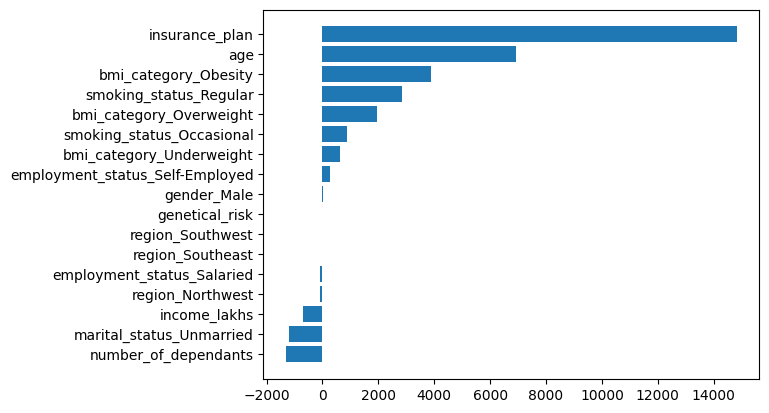

In [138]:
plt.barh(coef_df.index,coef_df['Coefficients'])
plt.show()

## Regularization

In [139]:
model_rg=Ridge(alpha=5)
model_rg.fit(x_train,y_train)
print('test score: ',model_rg.score(x_test,y_test))
print('train score: ',model_rg.score(x_train,y_train))

test score:  0.9103267979606597
train score:  0.9111068622921071


## XGBoost model

In [140]:
from xgboost import XGBRegressor
model_xg=XGBRegressor()

model_xg.fit(x_train,y_train)
print('test score: ',model_xg.score(x_test,y_test))
print('train score: ',model_xg.score(x_train,y_train))

test score:  0.9360604882240295
train score:  0.9572849869728088


In [141]:
# XGBoost is performing well so check its mean squared error
y_pred=model_xg.predict(x_test)

mse_lr=mean_squared_error(y_test,y_pred)
rmse_lr=np.sqrt(mse_lr)
print("XGBoost Regression ==>MSE: ",mse_lr,'RMSE: ',rmse_lr)

XGBoost Regression ==>MSE:  3025316.75 RMSE:  1739.343769931637


# Fine tuning

## Randoms search CV

In [142]:
model_xg=XGBRegressor()
param_grid={
    'n_estimators':[20,40,50],
    'learning_rate':[0.01,0.1,0.2],
    'max_depth':[3,4,5]
}

random_search=RandomizedSearchCV(model_xg,param_grid,n_iter=10,cv=3,scoring='r2',random_state=42)
random_search.fit(x_train,y_train)
random_search.best_score_

np.float64(0.9415034850438436)

In [143]:
best_model=random_search.best_estimator_

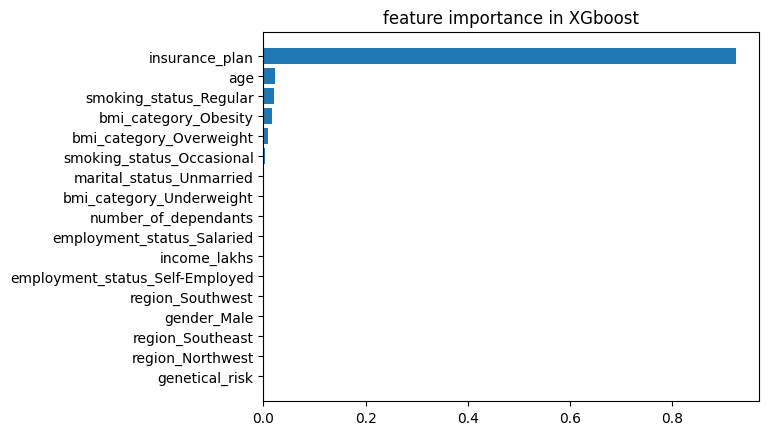

In [144]:
feature_imp=best_model.feature_importances_

coef_df=pd.DataFrame(feature_imp,index=x_test.columns,columns=['Coefficients'])
coef_df=coef_df.sort_values(by='Coefficients',ascending=True)
coef_df

plt.barh(coef_df.index,coef_df['Coefficients'])
plt.title('feature importance in XGboost')
plt.show()

# Error Analysis

In [145]:
y_pred=best_model.predict(x_test)

residuals=y_pred-y_test
residuals_pct=residuals*100/y_test

result_df=pd.DataFrame({
    'actual':y_test,
    'predicted':y_pred,
    'diff':residuals,
    'diff_pct':residuals_pct
})

result_df.head()

,actual,predicted,diff,diff_pct
19713,26895,26951.722656,56.722656,0.210904
14750,22734,19387.105469,-3346.894531,-14.721978
19932,21198,21655.195312,457.195312,2.156785
29643,9100,9829.094727,729.094727,8.012030
17076,26434,27037.996094,603.996094,2.284921


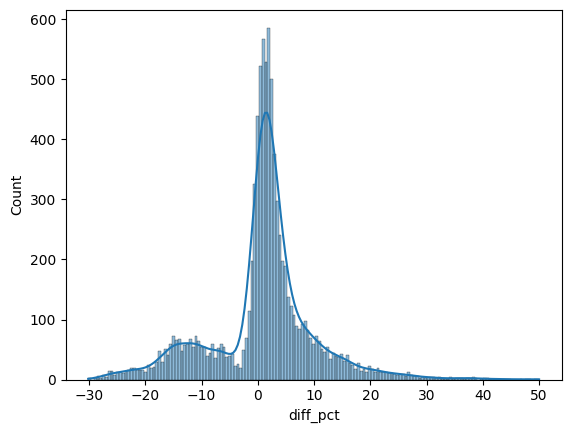

In [146]:
sns.histplot(result_df['diff_pct'],kde=True)
plt.show()

In [147]:
extreme_error_threshold=10
extreme_result_df=result_df[np.abs(result_df.diff_pct)>extreme_error_threshold]
extreme_result_df.shape

(2206, 4)

In [148]:
extreme_errors_pct=extreme_result_df.shape[0]*100/result_df.shape[0]
extreme_errors_pct

24.656309377444952

In [149]:
result_df[np.abs(result_df.diff_pct)>50].sort_values('diff_pct',ascending=False)

,actual,predicted,diff,diff_pct
6517,6552,9829.094727,3277.094727,50.016708


# Export model for rest dataset

In [157]:
from joblib import dump

dump(best_model,'artifacts/model_rest.joblib')

scaler_with_cols={
    'scaler':scaler,
    'cols_to_scale':cols_to_scale
}
dump(scaler_with_cols,'artifacts/scaler_rest.joblib')

['artifacts/scaler_rest.joblib']